# UMAP explorer: 3-D shapes and the effect of n_neighbors and min_dist 

Code for two figures of the post [Dimensionality Reduction & Embedding Visualization — UMAP](https://gprietos.github.io/posts/umap/): the mammoth example in the [overview](https://gprietos.github.io/posts/umap/#overview), and the interactive figure in [Effect of k and min_dist](https://gprietos.github.io/posts/umap/#effect-of-k-and-min_dist-hyperparameters).

The data are 3-D point clouds, so the original shape can be seen and compared with its 2-D UMAP: a mammoth (the Smithsonian scan used in PAIR's [Understanding UMAP](https://pair-code.github.io/understanding-umap/)), a swiss roll, two linked rings, a torus, and three Gaussian blobs of different sizes and densities.

**Warning:** the interactive explorer takes about ~25 minutes to compute the first time (the results are cached, so later runs are quick). To compute it faster, see [`scripts/`](../scripts/).

In [ ]:
import matplotlib.pyplot as plt

from umap_examples.config import EXPLORER_DIR
from umap_examples.plotting import plot_3d_vs_2d, save_figure
from umap_examples.reduction import compute_umap
from umap_examples.shapes import mammoth
from umap_examples.umap_explorer import export_widget_data
from umap_examples.widgets import show_umap_explorer

## The mammoth, from 3-D to 2-D

The mammoth from the post's overview, colored by body part. With k = 100 and min_dist = 0.5, UMAP flattens it but keeps every part attached and in order. With a small k it breaks into pieces.

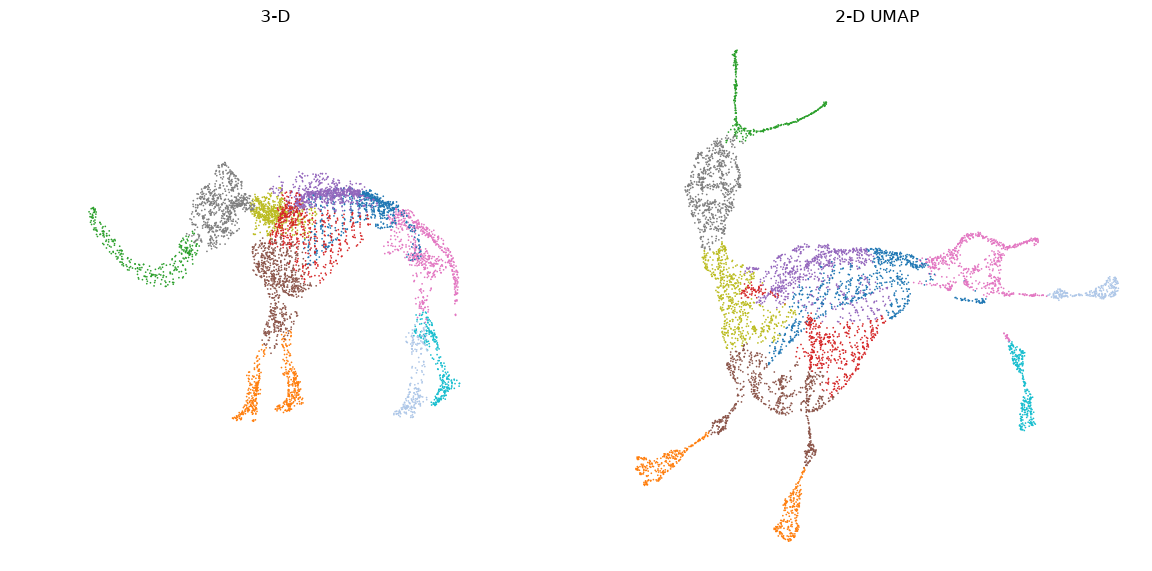

In [ ]:
X, labels = mammoth(n=6000)
points, _ = compute_umap(X, n_neighbors=100, min_dist=0.5, metric="euclidean")
fig = plot_3d_vs_2d(X, points, labels)
save_figure(fig, "intro_mammoth", dark=True)
plt.show()

## n_neighbors and min_dist Interactive explorer

The 3-D shape, which you can rotate, next to its 2-D UMAP for the chosen n_neighbors (k) and min_dist. Hover a point to find it in the other view. UMAP's axes have no meaning, so each layout is rotated or mirrored to line up with the k = 15, min_dist = 0.1 one, and moving a slider doesn't flip the picture. Only a static preview is shown here: rerun the cell to see the interactive figure, or [see it in the post](https://gprietos.github.io/posts/umap/#effect-of-k-and-min_dist-hyperparameters).

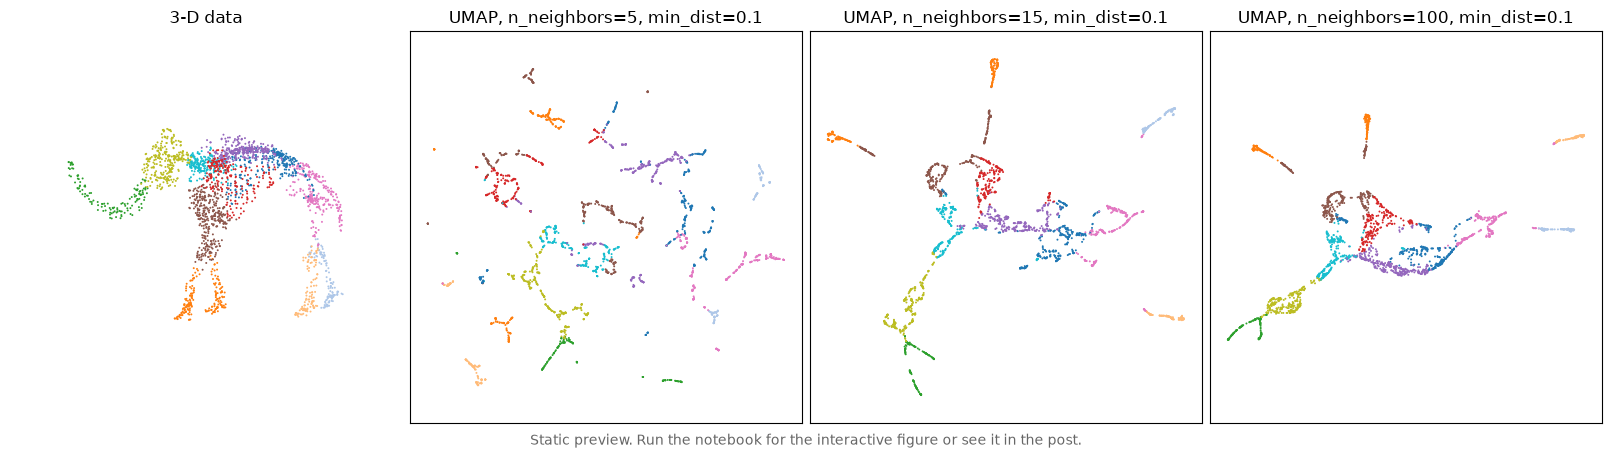

In [ ]:
if not (EXPLORER_DIR / "index.json").exists():
    export_widget_data()  # about 25 minutes, see the top of the notebook
show_umap_explorer()

## Things to try

- **n_neighbors (k)** sets the balance between local and global structure. A small k keeps fine detail but can break the shape into pieces (at k = 5 the mammoth, the swiss roll and the torus fall apart). A large k keeps the overall shape but loses detail.
- **min_dist** sets how tightly points are packed. Small values give dense clusters with clear gaps; large values spread the points more evenly (compare the blobs at min_dist = 0 and 0.8).

About specific shapes:

- **Swiss roll:** from k = 30 up, UMAP unrolls it into a flat strip with its colors in order. It keeps which points are neighbors, not the shape the points make in 3-D.
- **Linked rings and torus:** The two rings come out as two separate loops that are no longer linked.
- **Blobs:** the large, sparse blob comes out about as big as the two small, dense ones, so a cluster's size in UMAP says little about its spread ([lost density](https://gprietos.github.io/posts/umap/#umap-weaknesses)).